# Lista 6: Como nasce um assistente
**Caderno de atividades do Capítulo 6** | **A ginga dos números**, livro de exercícios | Professor Bruno Menezes | [repositório](https://github.com/brunoleomenezes/ginga-dos-numeros)

Nome: ______________________  Turma: ______________

O código de cada exercício já está nas células, com a saída visível, para você conferir. O ideal é **digitar** o código em um caderno seu, como pede a Lista em PDF, e usar este caderno para comparar. Execute as células **na ordem**: quase todas dependem das anteriores. Em caso de dúvida, use *Ambiente de execução > Reiniciar sessão e executar tudo*.

## Parte 1. Seis ferramentas novas de Python

### B1. Logaritmo e perda: np.log

A perda de um modelo de linguagem é o **menos logaritmo** da probabilidade dada à palavra certa. O **np.log** calcula o logaritmo natural (base e) de um número ou de uma tabela inteira, e o **np.exp** desfaz a conta.

In [1]:
# "import" traz uma biblioteca; numpy (apelidada np) faz contas com tabelas de números
import numpy as np

# np.array cria uma tabela (vetor) com quatro probabilidades, da certeza (1.0) até 1%
p = np.array([1.0, 0.5, 0.25, 0.01])
# np.log dá o logaritmo natural de cada número; o sinal de menos transforma em perda positiva
perda = -np.log(p)

# print mostra na tela um texto e, depois da vírgula, o valor da variável
print("probabilidade:", p)
# .round(4) arredonda cada número para 4 casas decimais, só para exibir
print("perda        :", perda.round(4))
# np.exp desfaz o logaritmo: e elevado à perda volta a 1/p (a perplexidade)
print("e^perda      :", np.exp(perda).round(4))

probabilidade: [1.   0.5  0.25 0.01]
perda        : [-0.      0.6931  1.3863  4.6052]
e^perda      : [  1.   2.   4. 100.]


Probabilidade 1 dá perda 0, e quanto menor a probabilidade, maior a perda. O exponencial da perda (e^perda) é a perplexidade: aqui, o inverso da probabilidade.

**SUA VEZ**

1. Calcule a perda de uma probabilidade de 0.9 e de 0.1. Qual é maior?
2. Descubra o que o Python diz para np.log(0). Por que isso importa em um modelo?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [2]:
# Espaço para os seus testes

### B2. Ordenar e acumular: argsort e cumsum

O top-p precisa ordenar as probabilidades e somá-las em sequência. O **np.argsort(-p)** devolve as posições da maior para a menor, e o **np.cumsum** faz a soma acumulada. O **np.searchsorted** acha em que posição a soma alcança um valor.

In [3]:
# Quatro probabilidades de próxima palavra (somam 1)
p = np.array([0.1, 0.5, 0.3, 0.1])

# np.argsort dá as posições em ordem crescente; com -p, a ordem fica da maior para a menor
ordem = np.argsort(-p)
# Mostra as posições ordenadas (a posição 1, com 0.5, vem primeiro)
print("posições da maior para a menor:", ordem)
# p[ordem] usa a lista de posições para reordenar as probabilidades
print("probabilidades ordenadas      :", p[ordem])

# np.cumsum faz a soma acumulada: cada número é a soma dele com todos os anteriores
acumulada = np.cumsum(p[ordem])
# Mostra a soma acumulada, que vai crescendo até 1
print("soma acumulada                :", acumulada)

# np.searchsorted acha a posição em que a soma alcança 0.85; +1 porque posições começam em 0
n = np.searchsorted(acumulada, 0.85) + 1
# Quantas palavras mais prováveis são precisas para juntar 85% (a ideia do top-p)
print("quantas palavras para chegar a 0.85:", n)

posições da maior para a menor: [1 2 0 3]
probabilidades ordenadas      : [0.5 0.3 0.1 0.1]
soma acumulada                : [0.5 0.8 0.9 1. ]
quantas palavras para chegar a 0.85: 3


A soma acumulada mostra quando o grupo das palavras mais prováveis alcança o limite desejado. O + 1 serve porque as posições começam em zero.

**SUA VEZ**

1. Troque 0.85 por 0.5 e veja quantas palavras bastam.
2. Troque p por [0.7, 0.1, 0.1, 0.1]. O resultado muda para 0.85?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [4]:
# Espaço para os seus testes

### B3. Um laço de treino com histórico

Treinar é repetir: calcular o erro, calcular o gradiente, mexer no peso. Um laço **for** repete, e uma lista guarda o histórico da perda para desenhar a curva depois. Aqui, o exemplo mais simples possível: encontrar o **w** que minimiza (w − 3)².

In [5]:
# Peso inicial: começamos longe da resposta, que é 3
w = 0.0
# Taxa de aprendizado: o tamanho de cada passo
taxa = 0.2
# [] cria uma lista vazia, que vai guardar a perda de cada passo
historico = []

# Laço for: repete o bloco recuado 8 vezes; range(8) dá os números de 0 a 7
for passo in range(8):
    # A perda mede o erro: (w - 3) ao quadrado, ** é a potência
    perda = (w - 3) ** 2
    # O gradiente (a derivada da perda) diz para que lado a perda sobe
    gradiente = 2 * (w - 3)
    # .append acrescenta a perda atual no fim da lista
    historico.append(perda)
    # Anda contra o gradiente, um passo do tamanho da taxa (a descida do gradiente)
    w = w - taxa * gradiente

# np.round arredonda a lista inteira para 4 casas e mostra a perda caindo
print("perda a cada passo:", np.round(historico, 4))
# round (do próprio Python) arredonda um só número; w chega perto de 3
print("w final:", round(w, 4))

perda a cada passo: [9.0000e+00 3.2400e+00 1.1664e+00 4.1990e-01 1.5120e-01 5.4400e-02
 1.9600e-02 7.1000e-03]
w final: 2.9496


A cada passo, w anda um pouco contra o gradiente, e a perda cai. É a descida do gradiente do Capítulo 3, e é o esqueleto de todo treino.

**SUA VEZ**

1. Troque a taxa por 1.0 e veja o que acontece. E por 0.01?
2. Troque (w - 3) por (w - 7) e o gradiente correspondente, e confira que w vai para 7.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [6]:
# Espaço para os seus testes

### B4. Números grandes: separador e notação científica

Contas de escala dão números enormes. Em uma f-string, **{x:,}** separa os milhares com vírgula, e **{x:.2e}** usa notação científica. Para o formato brasileiro, trocamos a vírgula por ponto com **.replace(",", ".")**.

In [7]:
# Um número enorme: a quantidade de pesos de um modelo do tamanho do GPT-3
x = 173946175488
# f-string: o f antes das aspas permite pôr valores entre chaves; ":," separa os milhares
print(f"{x:,}")
# ":.2e" escreve em notação científica com 2 casas (e+11 quer dizer vezes 10 elevado a 11)
print(f"{x:.2e}")
# .replace troca cada vírgula por ponto, no formato brasileiro
print(f"{x:,}".replace(",", "."))
# Dentro das chaves pode ir uma conta inteira: aqui, 6 vezes N vezes D (custo de treino)
print(f"{6 * 175e9 * 300e9:.2e}")

173,946,175,488
1.74e+11
173.946.175.488
3.15e+23


O e+11 quer dizer vezes 10 elevado a 11. Em notação científica, números gigantes cabem em uma linha e podem ser comparados de relance.

**SUA VEZ**

1. Escreva em notação científica o número 0.00042.
2. Calcule 12 * 4096**2 * 32 e escreva com separador de milhares.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [8]:
# Espaço para os seus testes

### B5. Vetor desejado (one-hot) e produto externo

O gradiente da pontuação é **p − y**, em que y vale 1 para a palavra certa e 0 nas demais (um vetor *one-hot*). E o gradiente dos pesos é o **produto externo** desse vetor pelo vetor de entrada, que o **np.outer** calcula.

In [9]:
# Probabilidades que o modelo deu a 3 palavras
p = np.array([0.2, 0.5, 0.3])
# np.zeros(3) cria um vetor com três zeros
y = np.zeros(3)
# Põe 1 na posição 1 (a segunda palavra, a certa): é o vetor one-hot
y[1] = 1.0

# p - y é o gradiente da pontuação: negativo só na palavra certa
print("p - y        :", p - y)

# Um vetor de entrada com 2 números
h = np.array([1.0, 2.0])
# Título da próxima saída
print("outer(p - y, h):")
# np.outer multiplica cada número de p - y por cada número de h: uma tabela 3 x 2
print(np.outer(p - y, h))

p - y        : [ 0.2 -0.5  0.3]
outer(p - y, h):
[[ 0.2  0.4]
 [-0.5 -1. ]
 [ 0.3  0.6]]


A palavra certa recebe gradiente negativo (a pontuação deve subir), e as demais recebem gradiente positivo (devem descer). O np.outer cria uma linha de pesos para cada palavra.

**SUA VEZ**

1. Se a palavra certa fosse a terceira (índice 2), qual seria p - y?
2. Confira o formato do resultado do np.outer com .shape.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [10]:
# Espaço para os seus testes

### B6. Gráfico com escala logarítmica

Em treino, os passos variam de 1 a milhares, e a curva da perda fica ilegível em escala normal. O **plt.semilogx** usa escala logarítmica no eixo horizontal, o **plt.axhline** traça uma linha horizontal de referência.

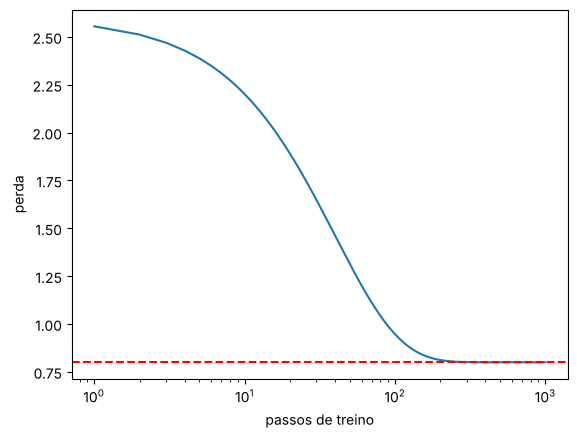

In [11]:
# matplotlib.pyplot (apelidado plt) é a biblioteca de gráficos
import matplotlib.pyplot as plt

# np.arange(1, 1001) cria os números de 1 a 1000 (o 1001 fica de fora)
passos = np.arange(1, 1001)
# Uma curva de perda inventada: começa em 2,6 e cai até o piso 0,8
perda = 0.8 + 1.8 * np.exp(-passos / 40)

# plt.semilogx desenha a curva com o eixo horizontal em escala logarítmica
plt.semilogx(passos, perda)
# plt.axhline traça uma linha horizontal tracejada ("--") e vermelha no piso 0,8
plt.axhline(0.8, linestyle="--", color="red")
# Nome do eixo horizontal
plt.xlabel("passos de treino")
# Nome do eixo vertical
plt.ylabel("perda")
# Mostra o gráfico
plt.show()

A curva cai rápido no começo e achata perto do piso tracejado. É o formato típico de uma curva de treino.

**SUA VEZ**

1. Troque semilogx por plot e compare.
2. Mude o piso de 0.8 para 1.2 na fórmula e na linha tracejada.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [12]:
# Espaço para os seus testes

## Parte 2. Os dez exercícios do capítulo

### Exercício 1. Dar um número ao erro: a perda do mini-Transformer
*Exemplo 1 do capítulo*

Vamos calcular a perda do mini-Transformer do Capítulo 5, com pesos arbitrários, no exemplo "o cliente enviou a".

In [13]:
# math é a biblioteca de matemática do próprio Python (aqui, para math.log)
import math

# Lista com as 6 palavras do vocabulário; a posição de cada uma é o seu número
vocab = ["o", "cliente", "enviou", "a", "nota", "folha"]
# Tabela 6 x 4: uma linha (vetor de 4 números) para cada palavra, os vetores de saída
EV = np.array([[1, 0, 0, 0.5], [0, 1, 0.5, 0], [0, 0.5, 1, 0],
               [1, 0, 0.5, 0], [0, 0, 0.5, 1], [0, 0.25, 0.25, 1]])
# vetor da última posição depois dos dois blocos (Exercício 9 do Capítulo 5)
h = np.array([0.18388808924906277, 0.41636916124096596, 1.0438676189275375, -1.6441248694175665])

# "def" cria uma função: um bloco de código com nome, que recebe z e devolve um resultado
def softmax(z):
    # Exponencial de cada número; subtrair o maior evita números gigantes e não muda o resultado
    e = np.exp(z - z.max())
    # "return" devolve o resultado: dividir pela soma faz as probabilidades somarem 1
    return e / e.sum()

# @ é o produto de matrizes; .T vira a tabela: dá uma pontuação para cada uma das 6 palavras
z = h @ EV.T
# Transforma as pontuações em probabilidades
p = softmax(z)
# .index acha a posição de "nota" na lista (a palavra certa, posição 4)
certa = vocab.index("nota")

# A perda: menos o logaritmo da probabilidade dada à palavra certa
perda = -np.log(p[certa])
# Mostra quanto o modelo apostou em "nota"
print("p(nota) =", round(p[certa], 4))
# Mostra a perda deste exemplo
print("perda = -ln p(nota) =", round(perda, 4))
# A perplexidade é e elevado à perda: equivale a hesitar entre umas 28 palavras
print("perplexidade =", round(np.exp(perda), 2))
# Para comparar: chutar ao acaso entre 6 palavras dá perda ln 6
print("chute uniforme: perda =", round(math.log(6), 4))

p(nota) = 0.0353
perda = -ln p(nota) = 3.3426
perplexidade = 28.29
chute uniforme: perda = 1.7918


A perda do modelo, 3,3426, é maior que a de chutar ao acaso entre 6 palavras, 1,7918. Com pesos arbitrários, o modelo está confiante na palavra errada.

**SUA VEZ**

1. Calcule a perda se o modelo tivesse dado 50% a "nota".
2. Explique, com suas palavras, por que a perda pode ser pior que a do chute uniforme.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [14]:
# Espaço para os seus testes

### Exercício 2. Um passo de gradiente: a palavra certa sobe
*Exemplo 2 do capítulo*

Vamos calcular o gradiente da perda em relação aos vetores de saída, dar um passo e repetir.

In [15]:
# Vetor desejado: zeros em tudo...
y = np.zeros(6)
# ...e 1 na posição da palavra certa (o vetor one-hot)
y[certa] = 1.0
# O gradiente da perda em relação às pontuações é p - y
gz = p - y
# Mostra o gradiente: negativo só em "nota", que deve subir
print("p - y:", gz.round(4))

# Gradiente dos vetores de saída: o produto externo de p - y pelo vetor h (tabela 6 x 4)
grad = np.outer(gz, h)
# Um passo de descida do gradiente com taxa 0.5: cria a nova tabela EV1
EV1 = EV - 0.5 * grad

# Função que calcula a perda e as probabilidades para uma tabela E de vetores de saída
def perda_de(E):
    # Pontuações e probabilidades com a tabela E
    q = softmax(h @ E.T)
    # Devolve dois valores de uma vez (uma tupla): a perda e as probabilidades
    return -np.log(q[certa]), q

# Recebe os dois valores devolvidos em duas variáveis
L1, p1 = perda_de(EV1)
# A probabilidade de "nota" subiu
print("p(nota) depois do passo:", round(p1[certa], 4))
# A de "enviou" (posição 2), que era a favorita, caiu
print("p(enviou) depois do passo:", round(p1[2], 4))
# Compara a perda antes e depois do passo
print("perda antes e depois:", round(perda, 4), round(L1, 4))
# A linha de "nota" na tabela original
print("vetor de nota antes:", EV[certa])
# A mesma linha depois do passo: ela se aproximou do vetor h
print("vetor de nota depois:", EV1[certa].round(4))

p - y: [ 0.0574  0.2775  0.3797  0.2199 -0.9647  0.0302]
p(nota) depois do passo: 0.3036
p(enviou) depois do passo: 0.2217
perda antes e depois: 3.3426 1.1921
vetor de nota antes: [0.  0.  0.5 1. ]
vetor de nota depois: [0.0887 0.2008 1.0035 0.207 ]


Em um passo, a palavra certa foi de 3,5% para 30,4% e a perda caiu de 3,3426 para 1,1921.

In [16]:
# conferência: gradiente por diferenças finitas
# Calcula o gradiente "no braço": mexe um pouquinho (eps) em cada peso e mede a perda
def num_grad(eps=1e-6):
    # np.zeros_like cria uma tabela de zeros do mesmo formato de EV (6 x 4)
    g = np.zeros_like(EV)
    # Laço sobre as linhas; .shape[0] é o número de linhas
    for i in range(EV.shape[0]):
        # Laço dentro do laço, sobre as colunas; .shape[1] é o número de colunas
        for j in range(EV.shape[1]):
            # .copy() faz uma cópia; soma eps a um só peso (o ";" separa dois comandos)
            a = EV.copy(); a[i, j] += eps
            # Outra cópia, agora com eps subtraído do mesmo peso
            b = EV.copy(); b[i, j] -= eps
            # Inclinação: diferença das perdas dividida pela distância 2 eps; [0] pega só a perda
            g[i, j] = (perda_de(a)[0] - perda_de(b)[0]) / (2 * eps)
    # Devolve a tabela de gradientes estimados
    return g
# np.abs dá o valor absoluto e .max o maior: a pior diferença entre as duas contas
print("máxima diferença entre as duas formas:", np.abs(num_grad() - grad).max())

# Recomeça da tabela original, sem estragar EV
E = EV.copy()
# Lista do histórico, já com a perda inicial
hist = [perda]
# Repete 10 passos; "_" é um nome para quando não usamos o contador
for _ in range(10):
    # Perda e probabilidades atuais (só q é usado a seguir)
    l, q = perda_de(E)
    # Um passo de descida do gradiente com a mesma fórmula do produto externo
    E = E - 0.5 * np.outer(q - y, h)
    # Guarda a perda depois do passo
    hist.append(perda_de(E)[0])
# A perda vai caindo a cada passo
print("perda em 10 passos:", np.round(hist, 3))

máxima diferença entre as duas formas: 3.35000194251478e-10
perda em 10 passos: [3.343 1.192 0.337 0.18  0.123 0.094 0.076 0.064 0.055 0.049 0.043]


As duas formas de calcular o gradiente coincidem (diferença da ordem de 1e-10). Repetindo o passo, a perda cai a 0,043 em dez passos, porque treinamos com um só exemplo.

**SUA VEZ**

1. Troque a taxa de 0.5 para 2.0 e veja o que acontece com a perda. É estável?
2. Explique por que decorar um exemplo é fácil e o treino real é difícil.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [17]:
# Espaço para os seus testes

### Exercício 3. Treinar de verdade: a descida do gradiente recupera as contagens
*Exemplo 3 do capítulo*

Vamos treinar um modelo de bigramas com descida do gradiente no corpus do Capítulo 4 e comparar com a contagem.

In [18]:
# Counter conta repetições (não chega a ser usado nesta célula)
from collections import Counter

# Lista de 12 frases: o corpus do Capítulo 4
corpus = ["o cliente enviou o documento", "o cliente pagou o imposto",
          "o contador revisou o documento", "o contador calculou o imposto",
          "a cliente enviou a nota", "a contadora revisou a nota",
          "o cliente enviou a nota", "a contadora calculou o imposto",
          "o contador pagou o imposto", "a cliente pagou a nota",
          "o cliente revisou o documento", "a contadora enviou o documento"]

# Compreensão de conjunto: {...} junta as palavras sem repetir; .split() quebra nos espaços
palavras = sorted({w for f in corpus for w in f.split()})
# Palavras que podem vir antes: o marcador de início <s> e as 12 palavras
entradas = ["<s>"] + palavras
# Palavras que podem vir depois: as 12 palavras e o marcador de fim </s>
saidas = palavras + ["</s>"]
# Compreensão de dicionário: liga cada palavra à sua posição; enumerate dá posição e palavra
ie = {w: i for i, w in enumerate(entradas)}
# O mesmo dicionário para as palavras de saída
io = {w: i for i, w in enumerate(saidas)}

# Tabela de contagens 13 x 13, começando em zero; len dá o tamanho da lista
CNT = np.zeros((len(entradas), len(saidas)))
# Percorre cada frase do corpus
for f in corpus:
    # A frase como lista de palavras, com os marcadores de início e fim
    t = ["<s>"] + f.split() + ["</s>"]
    # zip(t, t[1:]) forma os pares vizinhos; t[1:] é a fatia sem a primeira palavra
    for a, b in zip(t, t[1:]):
        # Soma 1 na casa (palavra de antes, palavra de depois): a contagem de bigramas
        CNT[ie[a], io[b]] += 1

# Total de pares contados
total = CNT.sum()
# Divide cada linha pela sua soma: a probabilidade da próxima palavra, pela contagem
P_cont = CNT / CNT.sum(axis=1, keepdims=True)
# Perda média das próprias contagens (só nas casas > 0): o piso, a entropia dos dados
piso = -(CNT[CNT > 0] * np.log(P_cont[CNT > 0])).sum() / total

# int tira o ".0"; .shape dá o formato da tabela
print("pares de palavras:", int(total), " tabela:", CNT.shape)
# Perda de quem chuta ao acaso entre 13 saídas
print("perda do chute uniforme: ln 13 =", round(math.log(13), 4))
# O piso e sua perplexidade: nenhum modelo de bigramas faz melhor neste corpus
print("piso (entropia dos dados):", round(piso, 4), " perplexidade:", round(math.exp(piso), 4))

pares de palavras: 72  tabela: (13, 13)
perda do chute uniforme: ln 13 = 2.5649
piso (entropia dos dados): 0.8005  perplexidade: 2.2268


São 72 pares e uma tabela 13x13. O piso, 0,8005, é a perda do melhor modelo de bigramas possível neste corpus: a perda das contagens.

In [19]:
# Softmax aplicado a cada linha de uma tabela (cada linha vira probabilidades)
def softmax_linhas(W):
    # axis=1 calcula o maior de cada linha; keepdims mantém o formato para a subtração
    e = np.exp(W - W.max(axis=1, keepdims=True))
    # Divide cada linha pela sua soma
    return e / e.sum(axis=1, keepdims=True)

# Pesos do modelo, todos zero: começa dando a mesma chance a tudo
W = np.zeros_like(CNT)
# Lista para guardar a curva de perda
curva = []
# 5001 passos de treino (de 0 a 5000)
for passo in range(5001):
    # Probabilidades atuais do modelo
    Pm = softmax_linhas(W)
    # Perda média sobre os 72 pares (entropia cruzada), guardada na curva
    curva.append(-(CNT * np.log(Pm)).sum() / total)
    # Passo do gradiente com taxa 10.0; "-=" subtrai e guarda em W
    W -= 10.0 * ((CNT.sum(axis=1, keepdims=True) * Pm - CNT) / total)

# Cabeçalho da tabela
print("passo  perda    perplexidade")
# Percorre alguns passos escolhidos, dados como uma tupla
for s in (0, 1, 10, 100, 1000, 5000):
    # ":5d" ocupa 5 espaços para inteiros; ":.4f" mostra 4 casas decimais
    print(f"{s:5d}  {curva[s]:.4f}   {math.exp(curva[s]):.3f}")

# Probabilidades finais do modelo treinado
Pf = softmax_linhas(W)
# Linha em branco
print()
# Maior diferença entre o modelo treinado e as contagens
print("maior diferença para as contagens:", round(np.abs(Pf - P_cont).max(), 4))
# Os dicionários ie e io dão linha e coluna: P(enviou | cliente) pelo treino
print("P(enviou | cliente), treinado:", round(Pf[ie["cliente"], io["enviou"]], 4))
# A mesma probabilidade pela contagem: os dois quase coincidem
print("P(enviou | cliente), contagem:", round(P_cont[ie["cliente"], io["enviou"]], 4))

passo  perda    perplexidade
    0  2.5649   13.000
    1  2.1923   8.956
   10  1.1278   3.089
  100  0.8258   2.284
 1000  0.8028   2.232
 5000  0.8010   2.228

maior diferença para as contagens: 0.0007
P(enviou | cliente), treinado: 0.4998
P(enviou | cliente), contagem: 0.5


Depois de 5.000 passos, a perda chega a 0,8010, a 0,0005 do piso, e as probabilidades coincidem com as das contagens (diferença máxima 0,0007).

**SUA VEZ**

1. Mude a taxa de 10.0 para 1.0 e veja quantos passos são necessários para chegar perto do piso.
2. Explique por que a perda não consegue ficar abaixo do piso.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [20]:
# Espaço para os seus testes

### Exercício 4. Quanto custa treinar: a conta de bolso de 6 × N × D
*Exemplo 4 do capítulo*

Vamos calcular o custo de treino de três modelos pela regra 6 × N × D e converter em tempo sob hipóteses de hardware.

In [21]:
# Atribuição múltipla: largura d e número de blocos do GPT-3 numa linha só
d_gpt, blocos = 12288, 96
# Conta de bolso dos pesos: 12 vezes d ao quadrado vezes o número de blocos
N_12 = 12 * d_gpt ** 2 * blocos
# Mostra com pontos de milhar
print("pesos pela conta 12 d² blocos:", f"{N_12:,}".replace(",", "."))

PICO = 312e12      # operações por segundo, pico de uma placa A100 (hipótese)
UTIL = 0.30        # aproveitamento (hipótese)
# Taxa efetiva: o pico vezes a fração aproveitada
TAXA = PICO * UTIL
# Mostra a taxa em notação científica
print(f"taxa efetiva por placa: {TAXA:.2e} operações/s")
# Linha em branco
print()

# Lista de tuplas: (nome, N = número de pesos, D = número de tokens de treino)
modelos = [("hipotético (20 tok/peso)", 1e9, 20e9),
           ("GPT-3", 175e9, 300e9),
           ("Chinchilla", 70e9, 1.4e12)]
# Cabeçalho da tabela
print("modelo                       6ND          GPU-dias     dias c/ 1000 GPUs")
# Cada volta desempacota a tupla em três variáveis
for nome, N, D in modelos:
    # Custo de treino pela regra 6 x N x D (número de operações)
    flops = 6 * N * D
    # Segundos de uma placa (custo / taxa), divididos por 86400 segundos de um dia
    gpu_dias = flops / TAXA / 86400
    # ":27s" reserva 27 espaços para o texto; ":10,.0f" usa separador e nenhuma casa decimal
    print(f"{nome:27s}  {flops:.2e}   {gpu_dias:10,.0f}   {gpu_dias / 1000:10.2f}".replace(",", "."))
# Linha em branco
print()
# 3.156e7 é o número de segundos em um ano
print("GPT-3 em anos de uma placa:", round(6 * 175e9 * 300e9 / TAXA / 3.156e7))
# O modelo de 1 bilhão de pesos dividido entre 8 placas
print("1 bilhão de pesos com 8 placas, em dias:", round(6 * 1e9 * 20e9 / TAXA / 8 / 86400, 1))

pesos pela conta 12 d² blocos: 173.946.175.488
taxa efetiva por placa: 9.36e+13 operações/s

modelo                       6ND          GPU-dias     dias c/ 1000 GPUs
hipotético (20 tok/peso)     1.20e+20           15         0.01
GPT-3                        3.15e+23       38.951        38.95
Chinchilla                   5.88e+23       72.709        72.71

GPT-3 em anos de uma placa: 107
1 bilhão de pesos com 8 placas, em dias: 1.9


Sob as hipóteses, o GPT-3 equivaleria a cerca de 107 anos de uma placa, ou 39 dias com mil placas. O Chinchilla, com mais dados, custa cerca de 1,9 vez mais. O modelo de 1 bilhão cabe em 1,9 dia de 8 placas.

**SUA VEZ**

1. Refaça a conta com UTIL = 0.15. O que acontece com o tempo?
2. Calcule 6 × N × D para um modelo de 2 bilhões de pesos e 40 bilhões de tokens.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [22]:
# Espaço para os seus testes

### Exercício 5. Quanta memória o cache de chaves e valores consome
*Exemplo 5 do capítulo*

Vamos calcular o cache de chaves e valores do mini-modelo e do GPT-3.

In [23]:
# Bytes do cache: 2 (chaves e valores) x blocos x palavras x d x bytes de cada número
def cache_bytes(blocos, palavras, d, bytes_por_numero=2):
    # bytes_por_numero=2 é um valor padrão, usado quando não se informa outro
    return 2 * blocos * palavras * d * bytes_por_numero

# Mini-modelo: 2 (chave e valor) x 2 blocos x 5 palavras x 4 números (conta números, não bytes)
print("mini-modelo: números guardados =", 2 * 2 * 5 * 4)
# GPT-3: 96 blocos, 2048 palavras, d = 12288
b = cache_bytes(96, 2048, 12288)
# Título
print("GPT-3, uma conversa de 2048 palavras:")
# Bytes com pontos de milhar
print("  bytes:", f"{b:,}".replace(",", "."))
# Em gigabytes: 1 GB = 1e9 bytes
print("  GB   :", round(b / 1e9, 2))
# Linha em branco
print()
# Dobrar o contexto dobra a memória do cache
print("com contexto dobrado (4096):", round(cache_bytes(96, 4096, 12288) / 1e9, 2), "GB")
# Cada conversa simultânea tem o seu próprio cache
print("100 conversas ao mesmo tempo:", round(100 * b / 1e9, 1), "GB")

mini-modelo: números guardados = 80
GPT-3, uma conversa de 2048 palavras:
  bytes: 9.663.676.416
  GB   : 9.66

com contexto dobrado (4096): 19.33 GB
100 conversas ao mesmo tempo: 966.4 GB


Uma conversa de 2.048 palavras ocupa cerca de 9,66 GB de cache. Dobrar o contexto dobra a memória, e cada conversa simultânea soma a sua parte.

**SUA VEZ**

1. Calcule o cache de um modelo com 32 blocos, d = 4096 e 8.000 palavras, em GB.
2. Explique por que janelas de contexto longas custam mais caro.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [24]:
# Espaço para os seus testes

### Exercício 6. O cache muda a ordem de grandeza do tempo de gerar
*Exemplo 6 do capítulo*

Vamos contar as linhas de atenção calculadas com e sem cache e conferir, no mini-modelo, que o cache dá o mesmo resultado.

In [25]:
# Sem cache, cada palavra nova recalcula as linhas de todas as anteriores
def linhas_sem_cache(n0, m):
    # Soma n0, n0 + 1, ..., n0 + m - 1; "//" é a divisão inteira
    return m * n0 + m * (m - 1) // 2

# Com cache, calcula o prompt uma vez e depois só uma linha por palavra nova
def linhas_com_cache(n0, m):
    # n0 linhas do prompt mais uma linha para cada uma das m - 1 palavras seguintes
    return n0 + (m - 1)

# Cabeçalho: n0 é o tamanho do prompt, m o número de palavras geradas
print("n0      m     sem cache      com cache   razão")
# Três situações, cada uma dada como um par (n0, m)
for n0, m in [(4, 3), (1000, 200), (8000, 1000)]:
    # Calcula as duas contagens numa linha só
    a, b = linhas_sem_cache(n0, m), linhas_com_cache(n0, m)
    # A razão a / b diz quantas vezes o cache economiza
    print(f"{n0:5d} {m:5d} {a:12,} {b:12,} {a / b:8.1f}".replace(",", "."))

n0      m     sem cache      com cache   razão
    4     3           15            6      2.5
 1000   200      219.900        1.199    183.4
 8000  1000    8.499.500        8.999    944.5


Com 1.000 palavras de prompt e 200 geradas, o cache reduz de 219.900 linhas para 1.199, cerca de 183 vezes.

In [26]:
# As 5 palavras do mini-modelo
tokens = ["o", "cliente", "enviou", "a", "nota"]
# Os vetores (de 4 números) dessas 5 palavras
E = np.array([[1, 0, 0, 0.5], [0, 1, 0.5, 0], [0, 0.5, 1, 0], [1, 0, 0.5, 0], [0, 0, 0.5, 1]])
# Matriz que gera as consultas (Q), de 4 para 2 números
Wq = np.array([[1.5, 0], [0.5, 2], [0, 1.5], [2, 0]])
# Matriz que gera as chaves (K)
Wk = np.array([[0, 0], [0, 2], [2, 1.5], [0, 0.5]])
# Matriz que gera os valores (V); dtype=float guarda como números decimais
Wv = np.array([[0, 0], [0, 1], [1, 0], [0, 1]], dtype=float)

# Atenção do jeito do Capítulo 5: todas as posições de uma vez
def atencao_completa(X):
    # Consultas, chaves e valores de todas as palavras
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    # Pontuações: consulta vezes chave, divididas pela raiz de 2 (o tamanho dos vetores)
    S = Q @ K.T / np.sqrt(2)
    # Máscara causal: np.tril guarda o triângulo de baixo; acima dele vira -infinito
    S = np.where(np.tril(np.ones((len(X), len(X)))) > 0, S, -np.inf)
    # Softmax de cada linha (o -infinito vira peso zero)
    e = np.exp(S - S.max(axis=1, keepdims=True))
    # Pesos que somam 1 vezes os valores: a média ponderada da atenção
    return (e / e.sum(axis=1, keepdims=True)) @ V

# Atenção do jeito da geração: uma palavra por vez, guardando chaves e valores
def atencao_com_cache(X):
    # Três listas vazias: cache de chaves, cache de valores e as saídas
    Kc, Vc, saida = [], [], []
    # Percorre as palavras na ordem, como na geração
    for x in X:
        # Consulta só da palavra atual
        q = x @ Wq
        # Acrescenta a chave e o valor da palavra atual ao cache (nada é recalculado)
        Kc.append(x @ Wk); Vc.append(x @ Wv)
        # Compreensão de lista: pontua a consulta contra cada chave já guardada
        s = np.array([q @ k for k in Kc]) / np.sqrt(2)
        # Softmax das pontuações
        e = np.exp(s - s.max())
        # Média ponderada dos valores guardados: a saída desta posição
        saida.append((e / e.sum()) @ np.array(Vc))
    # Junta as saídas numa tabela
    return np.array(saida)

# np.allclose diz se duas tabelas são iguais (a menos de erros mínimos de arredondamento)
print("completa e com cache dão o mesmo resultado?",
      np.allclose(atencao_completa(E), atencao_com_cache(E)))

completa e com cache dão o mesmo resultado? True


O resultado é idêntico (True). O cache não é uma aproximação: é o mesmo cálculo, com menos trabalho.

**SUA VEZ**

1. Calcule as linhas com e sem cache para um prompt de 500 palavras e 50 geradas.
2. Explique por que o cache gasta memória para economizar tempo.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [27]:
# Espaço para os seus testes

### Exercício 7. Temperatura, top-k e top-p sobre a mesma distribuição
*Exemplo 7 do capítulo*

Vamos aplicar temperatura, top-k e top-p à mesma distribuição de seis verbos.

In [28]:
# Seis verbos candidatos para a próxima palavra
verbos = ["enviou", "pagou", "revisou", "calculou", "emitiu", "arquivou"]
# Logits: as pontuações do modelo para cada verbo, antes do softmax
logits = np.array([3.0, 2.4, 1.9, 1.0, 0.2, -0.5])

# Softmax com temperatura T; T=1.0 é o valor padrão
def softmax_T(z, T=1.0):
    # Divide as pontuações por T: T < 1 acentua as diferenças, T > 1 achata
    e = np.exp(z / T - (z / T).max())
    # Normaliza para somar 1
    return e / e.sum()

# Top-k: mantém só as k palavras mais prováveis
def top_k(p, k):
    # Começa com tudo zero
    q = np.zeros_like(p)
    # Posições da maior para a menor; a fatia [:k] pega as k primeiras
    idx = np.argsort(-p)[:k]
    # Copia só as probabilidades dessas k posições
    q[idx] = p[idx]
    # Renormaliza para que as que sobraram somem 1
    return q / q.sum()

# Top-p: mantém as mais prováveis até a soma alcançar o limite
def top_p(p, limite):
    # Posições da maior para a menor
    ordem = np.argsort(-p)
    # Soma acumulada das probabilidades ordenadas
    acum = np.cumsum(p[ordem])
    # Quantas palavras são precisas para alcançar o limite (+1 porque começa em 0)
    n = int(np.searchsorted(acum, limite) + 1)
    # Começa com tudo zero
    q = np.zeros_like(p)
    # Copia as probabilidades das n primeiras posições da ordem
    q[ordem[:n]] = p[ordem[:n]]
    # Devolve a distribuição renormalizada, o número de palavras e a soma acumulada
    return q / q.sum(), n, acum

# Distribuição original (temperatura 1)
P1 = softmax_T(logits)
# Aplica o top-p com limite de 90%
Pp, n, acum = top_p(P1, 0.90)

# " ".join junta textos com espaço; ":>9s" alinha cada verbo à direita em 9 espaços
print("verbo        ", " ".join(f"{v:>9s}" for v in verbos))
# Linha de probabilidades com T = 1
print("T = 1        ", " ".join(f"{x:9.4f}" for x in P1))
# Temperatura baixa: a favorita fica ainda mais forte
print("T = 0,5      ", " ".join(f"{x:9.4f}" for x in softmax_T(logits, 0.5)))
# Temperatura alta: as chances ficam mais parecidas
print("T = 2        ", " ".join(f"{x:9.4f}" for x in softmax_T(logits, 2.0)))
# Top-k com k = 3: sempre três palavras
print("top-k = 3    ", " ".join(f"{x:9.4f}" for x in top_k(P1, 3)))
# Top-p com 0,90: o número de palavras depende da distribuição
print("top-p = 0,90 ", " ".join(f"{x:9.4f}" for x in Pp))
# Linha em branco
print()
# Mostra a soma acumulada que o top-p usou
print("soma acumulada (ordenada):", acum.round(4))
# Quantas palavras o top-p manteve
print("palavras mantidas pelo top-p:", n)

verbo            enviou     pagou   revisou  calculou    emitiu  arquivou
T = 1            0.4744    0.2603    0.1579    0.0642    0.0288    0.0143
T = 0,5          0.6969    0.2099    0.0772    0.0128    0.0026    0.0006
T = 2            0.3220    0.2385    0.1858    0.1184    0.0794    0.0559
top-k = 3        0.5314    0.2917    0.1769    0.0000    0.0000    0.0000
top-p = 0,90     0.4958    0.2721    0.1650    0.0671    0.0000    0.0000

soma acumulada (ordenada): [0.4744 0.7347 0.8926 0.9568 0.9857 1.    ]
palavras mantidas pelo top-p: 4


Três palavras somam 89,26%, que não chega a 90%, e por isso o top-p mantém quatro. O top-k tem tamanho fixo, e o top-p se adapta.

**SUA VEZ**

1. Aplique top-p = 0.5. Quantas palavras sobram?
2. Aplique top-p = 0.9 a uma distribuição em que uma palavra tem 95%. O que acontece?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [29]:
# Espaço para os seus testes

### Exercício 8. Perda só sobre a resposta: o ajuste por instruções
*Exemplo 8 do capítulo*

Vamos comparar a perda sobre todos os tokens com a perda só sobre a resposta, em um par fictício de pergunta e resposta.

In [30]:
# A sequência de treino, palavra por palavra: pergunta e resposta
seq = ["Pergunta", ":", "qual", "é", "o", "prazo", "do", "contrato", "?",
       "Resposta", ":", "trinta", "dias", "."]
# A probabilidade que o modelo deu a cada palavra certa da sequência
probs = np.array([0.02, 0.60, 0.05, 0.30, 0.25, 0.04, 0.50, 0.03, 0.40,
                  0.10, 0.85, 0.20, 0.65, 0.90])      # ilustrativas
# As 10 primeiras palavras são tratadas como a parte da pergunta
n_pergunta = 10

# A perda de cada palavra
perdas = -np.log(probs)
# zip anda nas três listas juntas: palavra, probabilidade e perda
for t, pr, l in zip(seq, probs, perdas):
    # ":10s" reserva 10 espaços para a palavra; ":.2f" e ":.3f" fixam as casas decimais
    print(f"{t:10s} p = {pr:.2f}   -ln p = {l:.3f}")
# Linha em branco
print()
# .mean() é a média: perda sobre a sequência inteira (o pré-treino)
print("perda média, todos os tokens :", round(perdas.mean(), 4))
# A fatia [:n_pergunta] pega as 10 primeiras perdas
print("perda média, só a pergunta   :", round(perdas[:n_pergunta].mean(), 4))
# A fatia [n_pergunta:] pega o resto: a perda que o ajuste por instruções usa
print("perda média, só a resposta   :", round(perdas[n_pergunta:].mean(), 4))

Pergunta   p = 0.02   -ln p = 3.912
:          p = 0.60   -ln p = 0.511
qual       p = 0.05   -ln p = 2.996
é          p = 0.30   -ln p = 1.204
o          p = 0.25   -ln p = 1.386
prazo      p = 0.04   -ln p = 3.219
do         p = 0.50   -ln p = 0.693
contrato   p = 0.03   -ln p = 3.507
?          p = 0.40   -ln p = 0.916
Resposta   p = 0.10   -ln p = 2.303
:          p = 0.85   -ln p = 0.163
trinta     p = 0.20   -ln p = 1.609
dias       p = 0.65   -ln p = 0.431
.          p = 0.90   -ln p = 0.105

perda média, todos os tokens : 1.6396
perda média, só a pergunta   : 2.0646
perda média, só a resposta   : 0.577


Sobre todos os tokens, a perda é 1,6396, e boa parte dela vem da pergunta (2,0646). Só sobre a resposta, é 0,5770. O ajuste por instruções treina o assistente a responder, e não a imitar perguntas.

**SUA VEZ**

1. Mude a probabilidade de "trinta" de 0.20 para 0.90. O que acontece com a perda da resposta?
2. Explique por que o conjunto de ajuste pode ser pequeno comparado ao do pré-treino.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [31]:
# Espaço para os seus testes

### Exercício 9. Aprender o que as pessoas preferem: o modelo de recompensa
*Exemplo 9 do capítulo*

Vamos calcular a probabilidade de uma resposta ser preferida a outra, a perda e um passo de gradiente no modelo de recompensa.

In [32]:
# A sigmoide transforma qualquer número numa probabilidade entre 0 e 1
def sig(x):
    # math.exp é a exponencial de um só número
    return 1 / (1 + math.exp(-x))

# Notas que o modelo de recompensa deu às respostas A e B
rA, rB = 1.2, 0.4
# Chance de A ser preferida: a sigmoide da diferença das notas
pAB = sig(rA - rB)
# Mostra essa chance
print("P(A preferida a B) =", round(pAB, 4))
# Se as pessoas escolheram A, a perda é menos o logaritmo dessa chance
print("perda se escolheram A:", round(-math.log(pAB), 4))
# Se escolheram B, usa a chance contrária, 1 - pAB
print("perda se escolheram B:", round(-math.log(1 - pAB), 4))

# Taxa de aprendizado
taxa = 0.5
# Passo do gradiente: a nota de A sobe na proporção de 1 - pAB
rA2 = rA + taxa * (1 - pAB)
# E a nota de B desce na mesma medida
rB2 = rB - taxa * (1 - pAB)
# Nova chance de A ser preferida
pAB2 = sig(rA2 - rB2)
# Linha em branco
print()
# As notas depois do passo
print("notas depois do passo:", round(rA2, 4), round(rB2, 4))
# A chance de A subiu
print("P(A preferida a B) depois:", round(pAB2, 4))
# E a perda caiu
print("perda depois:", round(-math.log(pAB2), 4))

P(A preferida a B) = 0.69
perda se escolheram A: 0.3711
perda se escolheram B: 1.1711

notas depois do passo: 1.355 0.245
P(A preferida a B) depois: 0.7521
perda depois: 0.2848


Se as pessoas escolheram A, a perda é baixa (0,3711). Um passo sobe a nota de A, desce a de B e leva a probabilidade de 0,6900 a 0,7521.

**SUA VEZ**

1. Refaça com rA = 0.4 e rB = 1.2 (o modelo favorecia B) e veja a perda se escolheram A.
2. Explique por que um assistente preferido pelas pessoas não é necessariamente mais verdadeiro.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [33]:
# Espaço para os seus testes

### Exercício 10. Quanto vale uma nota de teste
*Exemplo 10 do capítulo*

Vamos calcular o intervalo de Wilson para notas de teste de diferentes tamanhos e conferir, por força bruta, que ele tem a cobertura anunciada.

In [34]:
# Intervalo de Wilson para k acertos em n perguntas; z=1.96 dá 95% de confiança
def wilson(k, n, z=1.96):
    # A taxa de acerto observada
    p = k / n
    # Denominador comum da fórmula
    den = 1 + z * z / n
    # Centro do intervalo, puxado um pouco para 50%
    centro = (p + z * z / (2 * n)) / den
    # Meia largura do intervalo; math.sqrt é a raiz quadrada
    metade = z / den * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    # Devolve o limite inferior e o superior
    return centro - metade, centro + metade

# Cinco notas de teste, cada uma dada como (acertos, perguntas)
for k, n in [(80, 100), (800, 1000), (84, 100), (0, 100), (3, 100)]:
    # Calcula os dois limites
    lo, hi = wilson(k, n)
    # Mostra os limites em porcentagem; ":5.2f" usa 5 espaços e 2 casas
    print(f"{k:4d} de {n:4d}:  de {lo * 100:5.2f}%  a {hi * 100:5.2f}%")

  80 de  100:  de 71.12%  a 86.66%
 800 de 1000:  de 77.41%  a 82.36%
  84 de  100:  de 75.58%  a 89.90%
   0 de  100:  de  0.00%  a  3.70%
   3 de  100:  de  1.03%  a  8.45%


80 de 100 dá de 71,12% a 86,66%. Com 10 vezes mais perguntas, o intervalo estreita para 77,41% a 82,36%. E 0 erros em 100 não é taxa zero: pode chegar a 3,70%.

In [35]:
# comb(n, x) conta de quantos jeitos se escolhem x itens entre n
from math import comb

# 100 perguntas e 80 acertos
n, k = 100, 80
# O intervalo de Wilson desse caso
lo, hi = wilson(k, n)

# Chance de acertar k ou mais de n se a taxa verdadeira fosse p (distribuição binomial)
def cauda_superior(p):
    # sum soma a chance de cada resultado de 80 a 100 acertos
    return sum(comb(n, x) * p ** x * (1 - p) ** (n - x) for x in range(k, n + 1))

# Se a taxa verdadeira fosse o limite inferior, ver 80 ou mais seria raro (perto de 2,5%)
print("se a taxa verdadeira fosse o limite inferior, P(acertar 80 ou mais) =", round(cauda_superior(lo), 4))
# Lembrete do valor esperado
print("conferência: perto dos 2,5% de cada lado de um intervalo de 95%")

se a taxa verdadeira fosse o limite inferior, P(acertar 80 ou mais) =

 0.029
conferência: perto dos 2,5% de cada lado de um intervalo de 95%


Com a taxa verdadeira no limite inferior do intervalo, a chance de ver 80 acertos ou mais é 2,9%, perto dos 2,5% de cada lado esperados de um intervalo de 95% (o método de Wilson não é exato, é uma aproximação).

**SUA VEZ**

1. Calcule o intervalo para 90 acertos em 100 e para 9 em 10. Qual é mais estreito?
2. Escreva cinco perguntas que você faria a um fornecedor que diz que seu assistente acerta 95%.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [36]:
# Espaço para os seus testes

## Parte 3. As mesmas contas em poucas linhas (SciPy)

### D1. Perda de entropia cruzada com o SciPy
*compare com o Exercício 1*

In [37]:
# Do SciPy, o softmax pronto (apelidado sm_lib) e o log_softmax (logaritmo do softmax)
from scipy.special import softmax as sm_lib, log_softmax

# A perda do Exercício 1 numa linha: menos o log_softmax na posição da palavra certa
print("perda com log_softmax:", round(-log_softmax(z)[certa], 4))
# A perda que calculamos na mão no Exercício 1
print("perda na mão         :", round(perda, 4))
# np.isclose diz se os dois números são iguais a menos de arredondamento
print("iguais?", np.isclose(-log_softmax(z)[certa], perda))

perda com log_softmax: 3.3426
perda na mão         : 3.3426
iguais? True


O log_softmax calcula o logaritmo das probabilidades de forma numericamente estável, o que importa quando as probabilidades são minúsculas.

### D2. Intervalo de Wilson com o SciPy
*compare com o Exercício 10*

In [38]:
# binomtest faz contas com acertos e erros (a distribuição binomial)
from scipy.stats import binomtest

# Intervalo de 95% para 80 de 100 pelo método de Wilson, pronto
r = binomtest(80, 100).proportion_ci(confidence_level=0.95, method="wilson")
# O nosso intervalo do Exercício 10
lo, hi = wilson(80, 100)
# .low e .high são os limites que o SciPy devolve
print("scipy (Wilson):", round(r.low, 4), round(r.high, 4))
# Os dois resultados coincidem
print("na mão        :", round(lo, 4), round(hi, 4))

scipy (Wilson): 0.7112 0.8666
na mão        : 0.7112 0.8666


O SciPy tem o método de Wilson pronto, e o resultado coincide com a nossa conta. Escolher o método certo importa: o intervalo "ingênuo" (p ± 1,96 vezes o erro-padrão) falha com poucos casos e com taxas perto de 0 ou 1.

### Desafio final, sem código pronto
O PyTorch, que já vem instalado no Colab, traz `torch.softmax`, `torch.sort` e `torch.cumsum`. Leia a documentação e use-os para refazer o top-p do Exercício 7 sobre os mesmos números.

1. Compare o resultado com o do Exercício 7 usando `np.allclose` depois de converter o tensor com `.numpy()`.
2. Mude o limite do top-p para 0.5 e para 0.99 e explique, em uma célula de texto, como muda o número de palavras mantidas.
3. Explique por que o top-p se adapta a distribuições diferentes e o top-k não.

In [39]:
# Espaço para os seus testes

---
**Entrega:** *Ambiente de execução > Reiniciar sessão e executar tudo*, depois *Compartilhar > qualquer pessoa com o link pode visualizar*, e cole o link no espaço indicado pelo professor.